<a href="https://colab.research.google.com/github/elianyepez21/Sistema-de-Alerta-Mazar/blob/main/ProyectoFinal_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning aplicado a la Crisis Energética en Ecuador: Sistema de Alerta Temprana de Estrés Hídrico (2023 - 2025)

**Autor:** Elián Andino




---
<a id='setup'></a>
## Importación de Librerías

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, learning_curve, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
UMBRAL = 2120        # msnm: umbral de alerta
HORIZONTE = 14       # días hacia adelante que mira el target
PURGA = 14           # días que se separan entre entrenamiento y prueba (ver sección 5)
DEV_FIN = "2024-12-17"          # hasta aquí se desarrolla; 2025 queda como prueba final
RAPIDO = False                  # True = corrida corta de prueba
REPS, FOLDS = (2, 5) if RAPIDO else (10, 10)    # rúbrica: 10x10 (o 2x5 si es muy costoso)

---
<a id='introduction'></a>
## Introducción

Entre 2023 y 2024 Ecuador atravesó tres periodos de racionamiento eléctrico (octubre de 2023, abril de 2024 y
septiembre–diciembre de 2024) asociados a la sequía y al bajo nivel de los embalses [8]. El embalse Mazar es el
embalse más importante del complejo hidroeléctrico Paute. Anticipar que su nivel se acerca a una zona crítica permite
planificar el uso del agua y la generación con tiempo.

Este proyecto desarrolla un modelo supervisado de clasificación que funciona como **sistema de alerta temprana de estrés
hídrico**: con datos hidrológicos y de producción de CELEC (2023–2025), predice con **14 días de anticipación** si la
cota de Mazar llegará a **2 120 msnm o menos**.

**Sobre el umbral.** Según informes del operador reportados por la prensa, el mínimo de operación tradicional de Mazar es
2 115 msnm [9]. En este trabajo se usa 2 120 msnm como *umbral de alerta temprana*, esto debido a que en octubre de
2023 el racionamiento se anunció cuando la cota llegó a ese nivel [9]. Se repite el análisis con otros umbrales como
prueba de sensibilidad.


**¿Por qué la ventana de tiempo de 3 años?**

El periodo 2023–2025 incluye los tres episodios de crisis y también un año completo sin crisis (2025), que permite medir
falsas alarmas. **Limitaciones:** hay solo tres episodios reales, así que los resultados son orientativos; y 2025 no tiene
ningún día con alerta, por lo que no sirve para medir cuántas crisis detecta el modelo, solo cuántas falsas alarmas genera.

## 2. Carga de Datos y Variable target

Los datos se obtuvieron del portal de la Corporación Eléctrica del Ecuador (CELEC): 72 archivos CSV (12 meses × 3 años × 2 categorías), con información de hidrología (cotas y caudales) y de producción (energía generada por central).

Luego se relacionó mediante un **outer join** los registros de hidrología y producción de cada mes utilizando la feature **Fecha** como punto en común.

Por último, se ordenó cronológicamente el resultado para obtener el **Dataset Principal** que servirá de base para el modelado.




In [ ]:

meses = ["enero", "febrero", "marzo", "abril", "mayo", "junio",
         "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

def leer(archivo):
    d = pd.read_csv(archivo, encoding="utf-8-sig")
    d["Fecha"] = pd.to_datetime(d["Fecha"], format="%d/%m/%Y %H:%M:%S")
    return d

mensuales = []
for año in (2023, 2024, 2025):
    for mes in meses:
        archivos = [f"{tipo}_CSR_{mes}-{año}.csv" for tipo in ("Hidrología", "Producción")]
        if all(os.path.exists(a) for a in archivos):
            hidro, prod = leer(archivos[0]), leer(archivos[1])
            mensuales.append(hidro.merge(prod, on="Fecha", how="outer"))
        else:
            print("Falta el mes:", mes, año)

df = pd.concat(mensuales).drop_duplicates("Fecha").set_index("Fecha").sort_index().asfreq("D")
serie = df
print(f"{len(df)} días, del {df.index.min().date()} al {df.index.max().date()} | días sin ningún dato: {int(df.isna().all(axis=1).sum())}")

1096 días, del 2023-01-01 al 2025-12-31 | días sin ningún dato: 0


*Columnas principales:*
* `Fecha` - Marca temporal diaria del registro
* `Caudal*` - Caudales diarios de cada central (p. ej. `CaudalMaz`, `CaudalMol`)
* `Cota*` - Niveles de los embalses en msnm (p. ej. `CotaMaz`, `CotaMol`)
* `Energia*` - Generación diaria de cada central (p. ej. `EnergiaMaz`, `EnergiaMol`)
* **`estres_hidrico`** - Target: 1 si la cota de Mazar llegará a ≤ 2 120 msnm en alguno de los próximos 14 días.

**Etiquetado de la Variable Target (estres_hidrico)**

Se definió la variable objetivo (*target*), la cual es una variable de alerta temprana denominada **estres_hidrico**. Esta variable evaluará el estado futuro del embalse de Mazar con 14 días de anticipación:

- **0 (Operación Normal):** El nivel mínimo prospectivo del embalse en los próximos 14 días se mantendrá por encima del umbral de seguridad, indicando una operación estable.
- **1 (Alerta de Estrés Hídrico):** El nivel esperado en los próximos 14 días estará por debajo de la cota de 2,120 msnm.

In [ ]:
cota = df["CotaMaz"]

# cota mínima de los próximos 14 días: el mínimo móvil en t+14 cubre t+1 ... t+14
cota_min_futura = cota.rolling(HORIZONTE).min().shift(-HORIZONTE)
y_full = (cota_min_futura <= UMBRAL).astype(float).where(cota_min_futura.notna())   # NaN en los últimos 14 días

print("Clases (0 = normal, 1 = alerta):", y_full.value_counts().astype(int).to_dict())
for u in (2115, 2120, 2125, 2130):   # sensibilidad al umbral
    print(f"  umbral {u}: {int((cota_min_futura <= u).sum())} días en alerta")

# Columnas con datos faltantes
BASE = ["CaudalMaz", "CotaMaz", "CaudalMol", "CotaMol", "CaudalSop", "CotaSop",
        "CaudalMsf", "CotaMsf", "EnergiaMaz", "EnergiaMol", "EnergiaSop", "EnergiaMsf"]
nulos = df.isna().sum()
print("\nColumnas con nulos:", nulos[nulos > 0].to_dict())
print("Nulos en las 12 columnas base:", int(df[BASE].isna().sum().sum()))

Clases (0 = normal, 1 = alerta): {0.0: 877, 1.0: 205}
  umbral 2115: 106 días en alerta
  umbral 2120: 205 días en alerta
  umbral 2125: 270 días en alerta
  umbral 2130: 412 días en alerta

Columnas con nulos: {'CaudalCuencaPaute': 243, 'CaudalAgo': 30, 'CotaAgo': 30, 'CaudalMan': 92, 'CotaMan': 92, 'CaudalCCS': 61, 'CotaCCS': 61, 'EnergiaAgo': 196, 'EnergiaMan': 196, 'EnergiaCCS': 196}
Nulos en las 12 columnas base: 0


**Tratamiento de nulos.**

Se revisaron los datos nulos del dataset y se tomó la decisión de **no rellenar los valores nulos**, para no alterar la realidad del modelo. Lo evitamos por tres razones clave:

1. **Evitar "data leakage":** Rellenar datos hacia atrás implica usar información del futuro para predecir el pasado.
2. **No inventar información:** Hay variables con meses enteros en blanco; si las rellenamos, estaríamos fabricando datos falsos.
3. **Evitar conclusiones equivocadas:** Casi todos los datos faltantes coinciden en 2025, un año donde no hay alertas (etiqueta 0). Si el modelo ve esto, podría aprender por error que "si falta un dato = no hay peligro".


Por lo tanto, nos quedamos únicamente con las **12 variables 100% completas y confiables** (caudal, cota y energía de las 4 centrales principales). Además, descartamos la columna `EnergiaCsr` porque es solo un total que ya está sumado en las otras variables.

## 3. Análisis exploratorio (EDA)

**Balance de Datos**

Se cuenta la cantidad de días por clase (0: normal, 1: alerta), su porcentaje y su distribución por año. Hay un desbalance
moderado (≈ 19 % de positivos), pero lo más importante es que **los positivos están concentrados en pocos bloques de
tiempo y solo en 2023 y 2024**.

Distribución de Clases
CotaMaz
0    877
1    205

Porcentajes 
CotaMaz
0    81.05 %
1    18.95 %
Name: proportion, dtype: str

Días por clase y año
CotaMaz    0    1
row_0            
2023     322   43
2024     204  162
2025     351    0


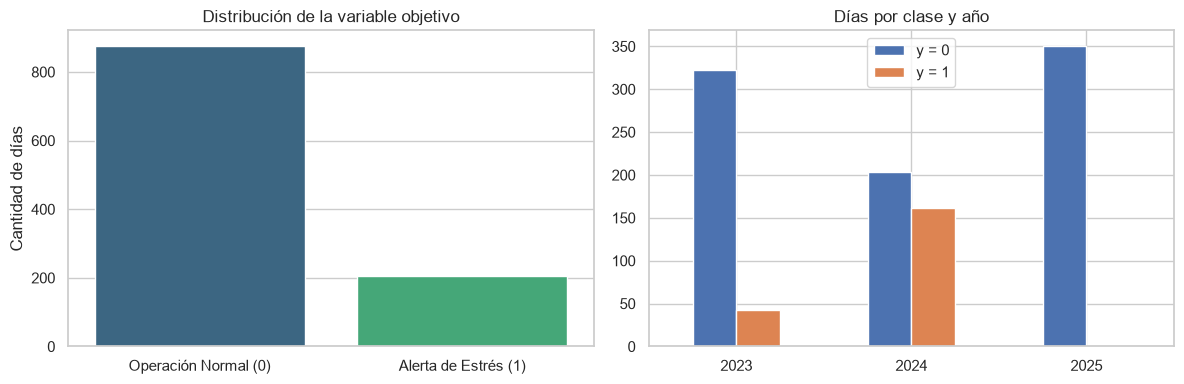

In [ ]:
y_all = y_full.dropna().astype(int)
print("Distribución de Clases")
print(y_all.value_counts().sort_index().to_string())
print("\nPorcentajes ")
print((y_all.value_counts(normalize=True).sort_index() * 100).round(2).astype(str) + " %")
print("\nDías por clase y año")
tabla_año = pd.crosstab(y_all.index.year, y_all)
print(tabla_año.to_string())

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=y_all.values, hue=y_all.values, palette="viridis", legend=False, ax=axs[0])
axs[0].set_xticks([0, 1]); axs[0].set_xticklabels(["Operación Normal (0)", "Alerta de Estrés (1)"])
axs[0].set_title("Distribución de la variable objetivo"); axs[0].set_ylabel("Cantidad de días")
tabla_año.plot.bar(ax=axs[1], rot=0); axs[1].set_title("Días por clase y año"); axs[1].set_xlabel("")
axs[1].legend(["y = 0", "y = 1"])
plt.tight_layout(); plt.show()

**Normalización**

Se comparan las escalas de las variables numéricas. Las cotas están en miles (msnm), los caudales en decenas o cientos y la
energía en miles de unidades. Para que ninguna variable domine por su magnitud, se aplicará `StandardScaler` dentro del pipeline.

Estadísticas Descriptivas (escalas actuales)


,mean,std,min,max
CaudalMaz,76.83,75.64,3.20,728.78
CotaMaz,2139.39,14.39,2106.66,2155.56
CaudalMol,110.04,90.36,9.72,909.25
CotaMol,1985.86,4.08,1971.65,1991.49
CaudalSop,93.84,36.99,0.00,187.06
CotaSop,1315.34,0.72,1313.41,1317.78
CaudalMsf,50.93,58.64,3.03,451.54
CotaMsf,788.62,4.50,757.13,792.82
EnergiaMaz,1472.83,1064.27,0.00,4085.23
EnergiaMol,12521.62,5770.19,0.00,26156.16


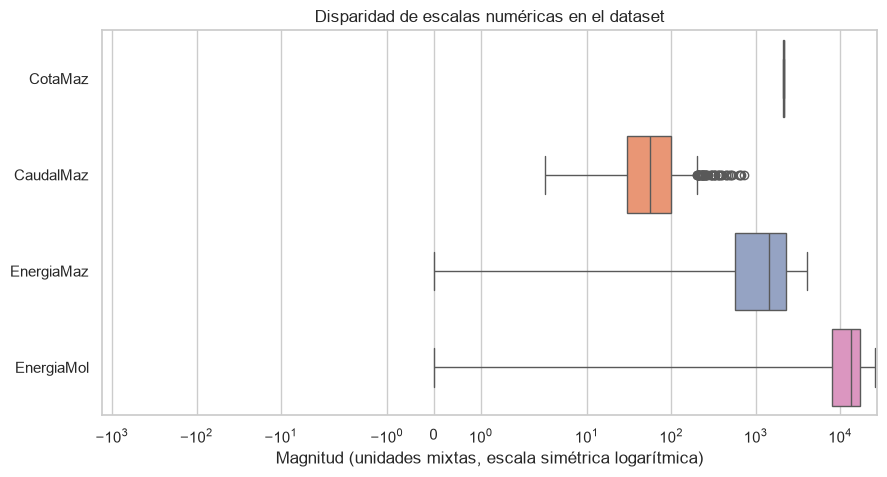

In [ ]:
print("Estadísticas Descriptivas (escalas actuales)")
display(df[BASE].describe().T[["mean", "std", "min", "max"]].round(2))

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[["CotaMaz", "CaudalMaz", "EnergiaMaz", "EnergiaMol"]], orient="h", palette="Set2")
plt.xscale("symlog"); plt.title("Disparidad de escalas numéricas en el dataset")
plt.xlabel("Magnitud (unidades mixtas, escala simétrica logarítmica)"); plt.show()

**Estacionalidad**

Se visualiza la manera en que el nivel del embalse de Mazar fluctua con el tiempo, con los días de alerta marcados en sombra.

Al analizarlo, notamos algo clave: las sequías no siguen un calendario **(no hay estacionalidad)**.
Esto se debe a que las crisis golpearon en momentos muy diferentes: finales de 2023, inicio y segundo semestre de 2024, y extrañamente, no ocurrieron en 2025, lo cual nos demuestra que estamos ante eventos irregulares.

Aunque no hay un calendario predecible, es necesario evaluar el modelo respetando el orden del tiempo por la **dependencia temporal** ya que en la hidrología, el nivel del agua de hoy es casi idéntico al nivel de ayer y al nivel de mañana.

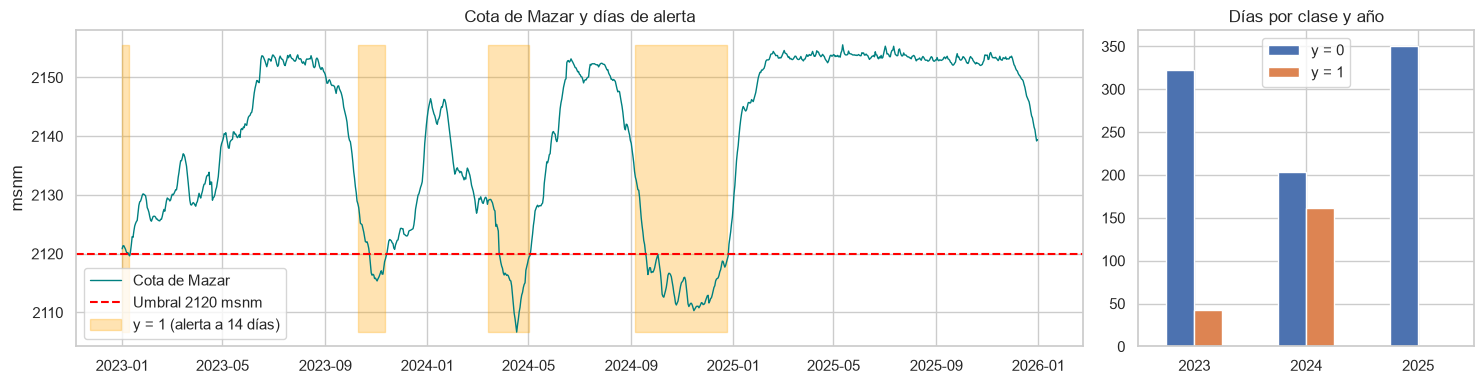

Proporción de alertas: 18.9%


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
axs[0].plot(cota, lw=1, color="teal", label="Cota de Mazar")
axs[0].axhline(UMBRAL, color="red", ls="--", label=f"Umbral {UMBRAL} msnm")
axs[0].fill_between(cota.index, cota.min(), cota.max(), where=(y_full == 1).values,
                    color="orange", alpha=0.3, label="y = 1 (alerta a 14 días)")
axs[0].set_title("Cota de Mazar y días de alerta"); axs[0].set_ylabel("msnm"); axs[0].legend(loc="lower left")

yy = y_full.dropna().astype(int)
pd.crosstab(yy.index.year, yy).plot.bar(ax=axs[1], rot=0)
axs[1].set_title("Días por clase y año"); axs[1].set_xlabel(""); axs[1].legend(["y = 0", "y = 1"])
plt.tight_layout(); plt.show()
print(f"Proporción de alertas: {yy.mean():.1%}")

**Asimetría (Skewness)**

Se calcula el coeficiente de asimetría de las variables base. Los **caudales** tienen un sesgo positivo alto: casi siempre
son bajos, con picos extremos por lluvias intensas. Para corregirlo se aplica una transformación `log1p`, pero **solo a las
variables con sesgo positivo alto** (|skew| > 1 y valores no negativos). Las cotas tienen sesgo *negativo*: `log1p`
no corrige ese tipo de asimetría (la empeora), por eso no se transforman.

Skewness de las variables base:
CaudalMol     3.69
CaudalMaz     3.48
CaudalMsf     2.77
EnergiaMaz    0.35
EnergiaMsf    0.29
CotaSop       0.18
CaudalSop    -0.27
EnergiaMol   -0.38
EnergiaSop   -0.40
CotaMol      -0.45
CotaMaz      -0.54
CotaMsf      -3.55

Variables base con transformación log1p (skew > 1 y valores ≥ 0): ['CaudalMaz', 'CaudalMol', 'CaudalMsf']


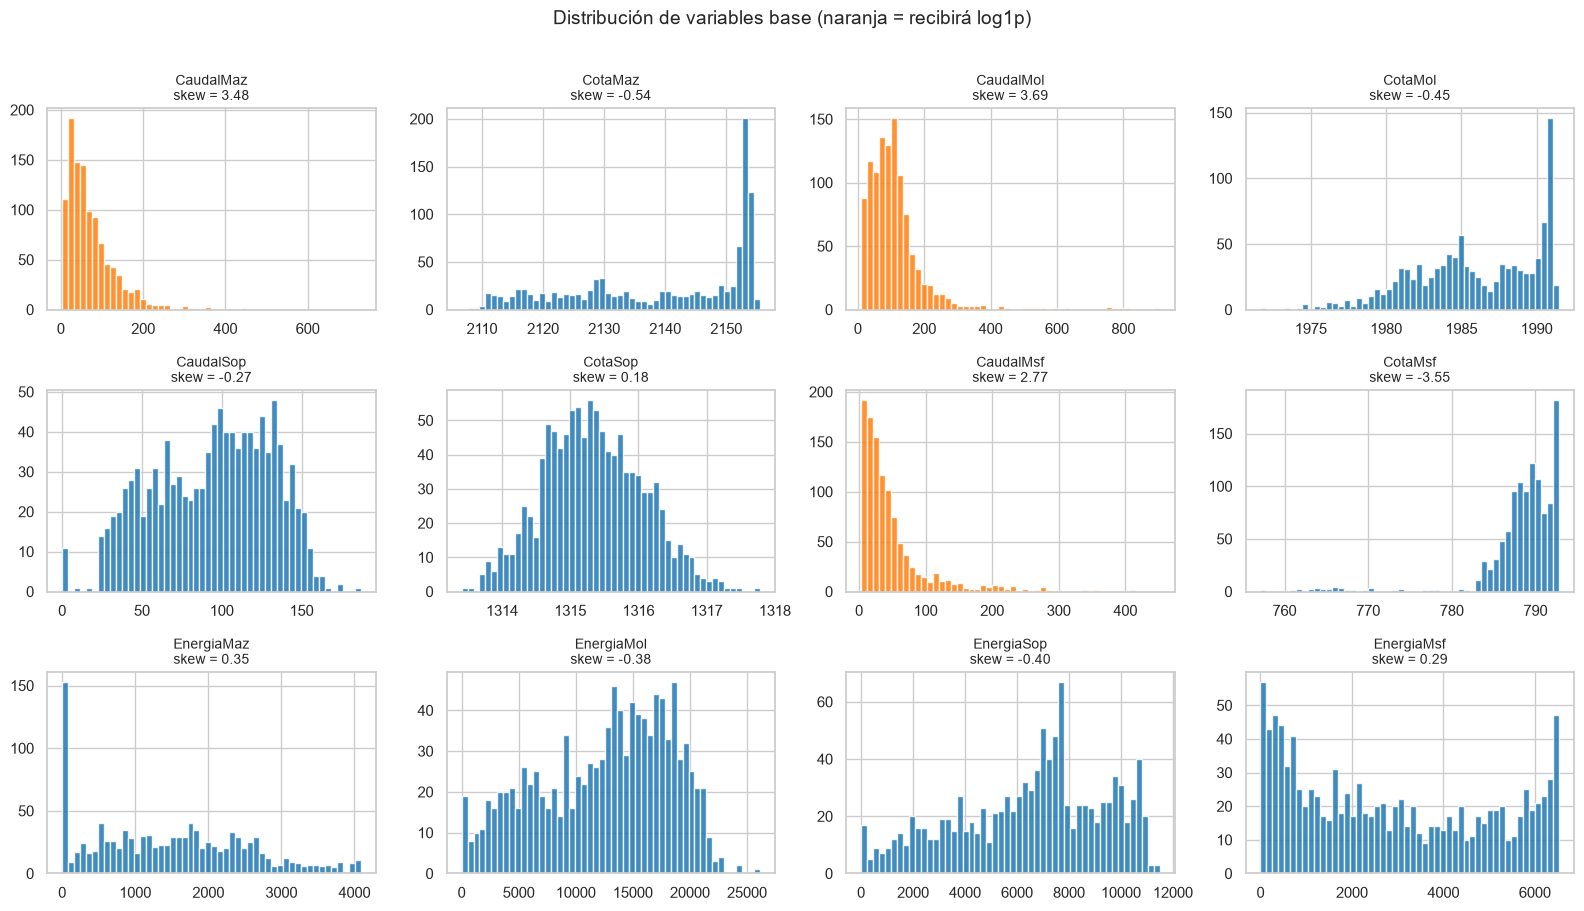

In [ ]:
skew = df[BASE].skew().sort_values(ascending=False)
print("Skewness de las variables base:"); print(skew.round(2).to_string())

LOG_BASE = [c for c in BASE if skew[c] > 1 and df[c].min() >= 0]
print("\nVariables base con transformación log1p (skew > 1 y valores ≥ 0):", LOG_BASE)

fig, axes = plt.subplots(3, 4, figsize=(16, 9)); axes = axes.flatten()
for i, col in enumerate(BASE):
    color = "#ff7f0e" if col in LOG_BASE else "#1f77b4"
    axes[i].hist(df[col].dropna(), bins=50, color=color, edgecolor="white", alpha=0.85)
    axes[i].set_title(f"{col}\nskew = {skew[col]:.2f}", fontsize=10)
plt.suptitle("Distribución de variables base (naranja = recibirá log1p)", fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

**Relación física entre generación y cota**

Si hay más generación en Mazar, la cota debería bajar más ese día. Se mide la correlación entre el cambio diario de la cota y la energía generada. Es una relación **moderada**, que motiva incluir las variables de producción.

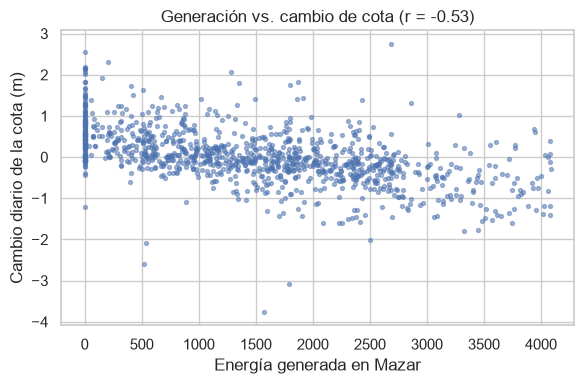

Correlación entre el cambio diario de la cota y EnergiaMaz: -0.53


In [ ]:
dcota = cota.diff()
r_fis = dcota.corr(df["EnergiaMaz"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["EnergiaMaz"], dcota, s=8, alpha=0.5)
ax.set_xlabel("Energía generada en Mazar"); ax.set_ylabel("Cambio diario de la cota (m)")
ax.set_title(f"Generación vs. cambio de cota (r = {r_fis:.2f})"); plt.tight_layout(); plt.show()
print(f"Correlación entre el cambio diario de la cota y EnergiaMaz: {r_fis:.2f}")

## 4. Variables de entrada y Feature Selection

**Feature Engineering**

Para que el algoritmo no analice cada día de forma aislada, creamos nuevas variables que le otorgan memoria y contexto. Partiendo del nivel de agua de hoy, le enseñamos al modelo a detectar tendencias calculando qué pasó en los días anteriores (rezagos), a qué velocidad se está vaciando la represa (pendientes) y una proyección matemática de cuántos días faltan para tocar el umbral crítico.

Todo esto se construye bajo una regla estricta de cero fuga de datos (Data Leakage): jamás se utiliza información del futuro. No rellenamos valores nulos inventando datos y evaluamos al modelo respetando estrictamente el orden cronológico, garantizando que el sistema prediga la sequía exactamente como lo haría en una sala de crisis real.

In [ ]:

X = pd.DataFrame(index=df.index)
for c in BASE:
    X[c] = df[c]
    for L in (1, 7, 14):
        X[f"{c}_lag{L}"] = df[c].shift(L)
    X[f"{c}_media7"] = df[c].rolling(7).mean()
for d in (3, 7, 14):
    X[f"pend_cota_{d}d"] = (cota - cota.shift(d)) / d          # pendiente de la cota (m/día)
X["cota_extrap14"] = cota + HORIZONTE * X["pend_cota_7d"]      # cota proyectada a 14 días

validas = y_full.notna() & X.notna().all(axis=1)               # se pierden las filas con rezagos incompletos
X, y = X[validas], y_full[validas].astype(int)

X_dev, y_dev = X.loc[:DEV_FIN], y.loc[:DEV_FIN]                # desarrollo: 2023 → 17/12/2024
X_test, y_test = X.loc["2025":], y.loc["2025":]                # prueba final: 2025
print(f"{X.shape[1]} variables | desarrollo: {len(X_dev)} filas ({int(y_dev.sum())} alertas) | 2025: {len(X_test)} filas ({int(y_test.sum())} alertas)")

64 variables | desarrollo: 703 filas (188 alertas) | 2025: 351 filas (0 alertas)


**Feature Selection (filtro).**

Se usa el filtro ANOVA (`SelectKBest` con `f_classif`) dentro del pipeline (sección 5), de modo
que se ajusta solo con los datos de entrenamiento de cada fold. Aquí se muestran las 10 variables con mayor puntaje en desarrollo.

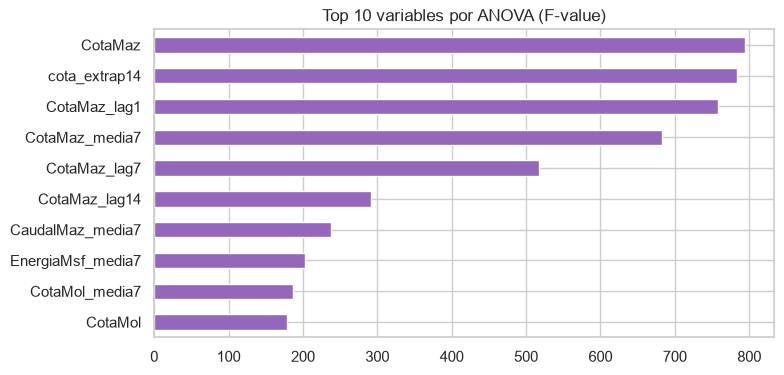

In [ ]:
puntajes = pd.Series(f_classif(StandardScaler().fit_transform(X_dev), y_dev)[0], index=X_dev.columns).nlargest(10)
puntajes[::-1].plot.barh(figsize=(8, 4), color="tab:purple")
plt.title("Top 10 variables por ANOVA (F-value)"); plt.show()

## 5. Validación, Selección de Modelos y Pipelines

**Validación**

Para evaluar el modelo de forma justa, no podemos mezclar los datos al azar ni usar un simple corte por fechas (división 80-20), ya que esto último nos obligaría a examinarlo en el año 2025, un periodo sin sequías donde el algoritmo no tendría verdaderas alertas que detectar (0 casos positivos).

La solución fue diseñar un sistema de validación propio que agrupa la información en bloques de 14 días para no romper el flujo del tiempo, asegura matemáticamente que se contenga días de crisis reales (Stratified K-fold CV), e inserta una "zona ciega" de dos semanas justo en la frontera entre los datos de entrenamiento y los de prueba. Esta barrera protectora, conocida como purga temporal, elimina cualquier riesgo de fuga de datos al hacerle imposible al modelo ver datos futuros para acertar en el presente.

In [ ]:

class KFoldPorBloques:
    """K-fold repetido, estratificado, por bloques de 14 días y con purga de PURGA días."""
    def __init__(self, n_splits=5, n_repeats=1, seed=SEED):
        self.n_splits, self.n_repeats, self.seed = n_splits, n_repeats, seed

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits * self.n_repeats

    def split(self, X, y=None, groups=None):
        dias = np.asarray((X.index - X.index[0]).days)
        for r in range(self.n_repeats):
            kf = StratifiedGroupKFold(self.n_splits, shuffle=True, random_state=self.seed + r)
            for tr, te in kf.split(X, y, dias // 14):                                  # un bloque = 14 días
                cerca = (np.abs(dias[tr][:, None] - dias[te][None, :]) <= PURGA).any(axis=1)
                yield tr[~cerca], te                                                    # se quitan los días cercanos

print("Alertas en cada fold de prueba:", [int(y_dev.iloc[te].sum()) for _, te in KFoldPorBloques(5).split(X_dev, y_dev)])

Alertas en cada fold de prueba: [40, 40, 31, 38, 39]


**Selección de Modelos**

Para este proyecto decidimos entrenar y comparar dos algoritmos con naturalezas totalmente distintas. Esto nos permite evaluar si necesitamos un sistema complejo o si uno simple es suficiente:

1. **Regresión Logística:** Es nuestro punto de referencia (*baseline*). Su gran ventaja es que nos permite leer cómo cada variable afecta el resultado. Con él, podemos explicar qué factor (ej. la caída de la cota) disparó la alarma de sequía.


2. **Random Forest :** Al ser un conjunto de múltiples árboles de decisión, tiene la capacidad de descubrir patrones "no lineales" e interacciones complejas que la regresión simple no detecta (por ejemplo, cómo se combina un caudal bajo repentino con una alta generación en fin de semana).


**Pipeline**

Para evitar data leakage, cada evaluación ejecuta un flujo de cuatro pasos ajustado únicamente con datos de entrenamiento:

1. **`log1p`:** Suaviza los picos extremos de los caudales (outliers).
2. **`StandardScaler`:** Normaliza la escala de todas las variables.
3. **`SelectKBest`:** Conserva solo las columnas con verdadero poder predictivo.
4. **Clasificación:** Entrena el algoritmo priorizando los días de alerta (`class_weight`) para compensar que casi no hay crisis en el historial.

In [ ]:
LOG_COLS = [c for c in X.columns if c.split("_")[0] in LOG_BASE]   # caudales y sus rezagos / medias

def crear_pipeline(modelo):
    log = ColumnTransformer([("log", FunctionTransformer(np.log1p), LOG_COLS)], remainder="passthrough")
    return Pipeline([("log", log), ("escala", StandardScaler()),
                     ("filtro", SelectKBest(f_classif, k=20)), ("modelo", modelo)])

lr = LogisticRegression(class_weight="balanced", max_iter=3000)
rf = RandomForestClassifier(n_estimators=150, class_weight="balanced_subsample", random_state=SEED)

## 6. Optimización de hiperparámetros

Se aplica (`GridSearchCV`) con el repeated k-fold por bloques (5 folds × 3 repeticiones). Se optimiza el número de
variables que deja el filtro (`k`) y los hiperparámetros de cada modelo.

La métrica es la **PR-AUC** (`average_precision`),más informativa que el accuracy o la ROC cuando la clase positiva es minoritaria [6].

In [ ]:

cv = KFoldPorBloques(n_splits=5, n_repeats=1 if RAPIDO else 3)
busqueda = {
    "Regresión logística": (crear_pipeline(lr), {"filtro__k": [10, 20, 40], "modelo__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (crear_pipeline(rf), {"filtro__k": [10, 30], "modelo__max_depth": [3, 6, None],
                                          "modelo__min_samples_leaf": [3, 10]}),
}
mejores = {}
for nombre, (pipe, grid) in busqueda.items():
    gs = GridSearchCV(pipe, grid, scoring="average_precision", cv=cv, n_jobs=-1).fit(X_dev, y_dev)
    mejores[nombre] = gs.best_estimator_
    print(f"{nombre}: {gs.best_params_} | PR-AUC en validación = {gs.best_score_:.3f}")

Regresión logística: {'filtro__k': 10, 'modelo__C': 1} | PR-AUC en validación = 0.921
Random Forest: {'filtro__k': 30, 'modelo__max_depth': 6, 'modelo__min_samples_leaf': 3} | PR-AUC en validación = 0.897


**Gráficas: Optimización de Hiperparámetros y Curva de aprendizaje**


(1) Optimización de λ = 1/C, la fuerza de regularización de la regresión logística

(2) curvas de aprendizaje de ambos modelos.

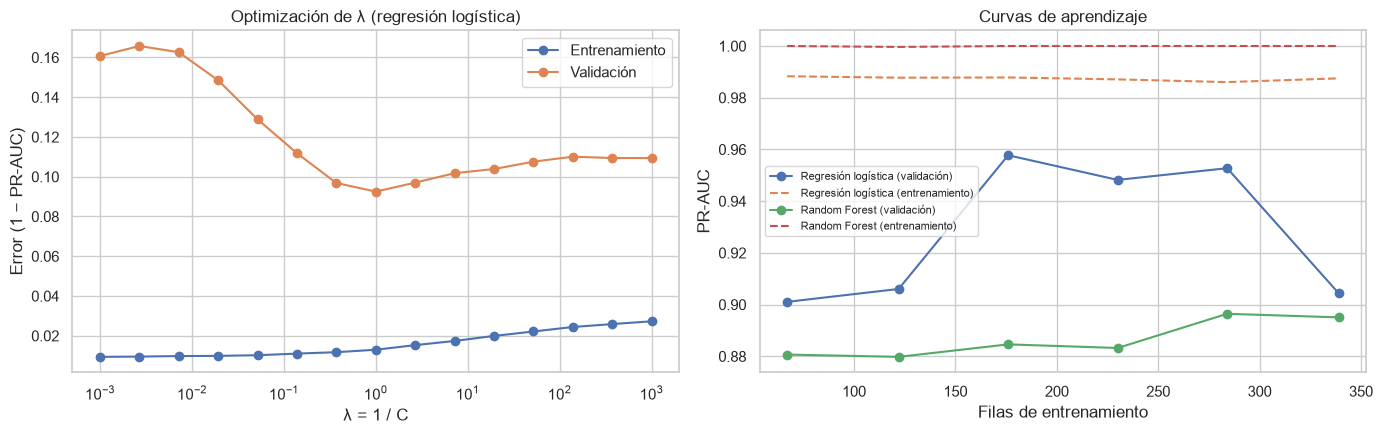

In [ ]:
Cs = np.logspace(3, -3, 15)
tr, va = validation_curve(mejores["Regresión logística"], X_dev, y_dev, param_name="modelo__C",
                          param_range=Cs, cv=KFoldPorBloques(5), scoring="average_precision")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].plot(1 / Cs, 1 - tr.mean(axis=1), marker="o", label="Entrenamiento")
axs[0].plot(1 / Cs, 1 - va.mean(axis=1), marker="o", label="Validación")
axs[0].set_xscale("log"); axs[0].set_xlabel("λ = 1 / C"); axs[0].set_ylabel("Error (1 − PR-AUC)")
axs[0].set_title("Optimización de λ (regresión logística)"); axs[0].legend()

for nombre, modelo in mejores.items():
    n, tr, va = learning_curve(modelo, X_dev, y_dev, cv=KFoldPorBloques(5), train_sizes=np.linspace(0.2, 1, 6),
                               scoring="average_precision", shuffle=True, random_state=SEED)
    axs[1].plot(n, va.mean(axis=1), marker="o", label=f"{nombre} (validación)")
    axs[1].plot(n, tr.mean(axis=1), "--", label=f"{nombre} (entrenamiento)")
axs[1].set_xlabel("Filas de entrenamiento"); axs[1].set_ylabel("PR-AUC")
axs[1].set_title("Curvas de aprendizaje"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Comparación estadística de dos técnicas

Se comparan **Regresión Logística** y **Random Forest** con **10 repeticiones × 10 folds**  y aplicamos la **prueba de Wilcoxon** para confirmar si la ventaja de un modelo es estadísticamente significativa.

**1.¿Por qué usar Machine Learning?**
Para probar que el uso de un modelo de Machine Learning es justificado, comparamos los modelos contra dos reglas tradicionales sin aprendizaje:
* **Persistencia:** Asume que la cota de hoy no cambiará en 14 días.
* **Extrapolación Lineal:** Proyecta la caída del agua trazando una línea recta con la tendencia reciente.

**2. Métricas de Evaluación:**
* **PR-AUC Global:** Rendimiento general del modelo en todo el historial.
* **PR-AUC en Días de Inicio:** La prueba de fuego. Evalúa la **capacidad de alerta temprana** analizando únicamente los días en que el embalse aún está lleno pero se vaciará en 14 días.


100 particiones (10 repeticiones × 10 folds)
                         ap  ap_inicio
modelo                                
Extrapolación lineal  0.949      0.858
Regresión logística   0.942      0.757
Persistencia          0.959      0.687
Random Forest         0.911      0.605
RF sin producción     0.919      0.582


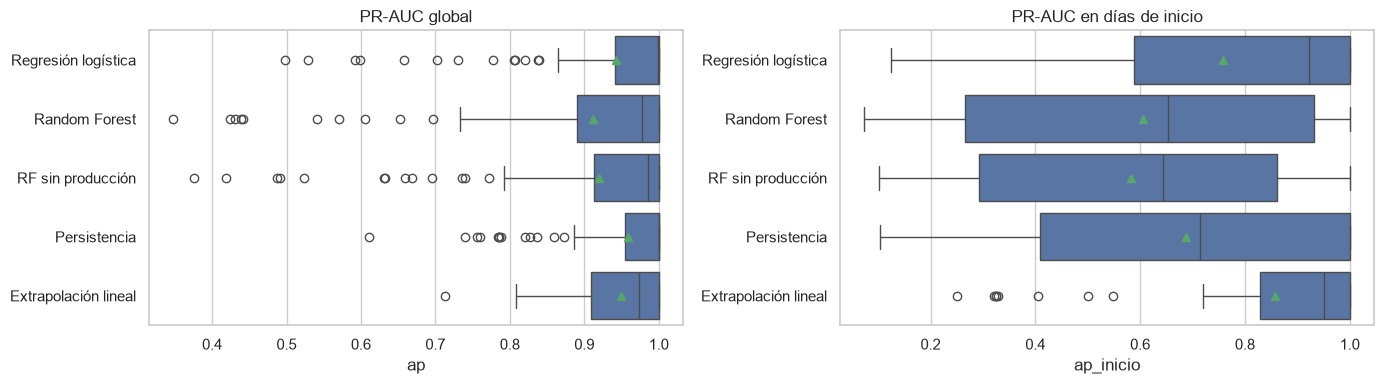

In [ ]:

sin_produccion = [c for c in X_dev.columns if "Energia" not in c]

def pr_auc(y_real, puntaje, Xt):
    """PR-AUC global y PR-AUC solo en días de inicio (cota de hoy > umbral)."""
    inicio = (Xt["CotaMaz"] > UMBRAL).values
    ap_inicio = average_precision_score(y_real[inicio], puntaje[inicio]) if y_real[inicio].sum() > 0 else np.nan
    return average_precision_score(y_real, puntaje), ap_inicio

filas = []
for i, (tr, te) in enumerate(KFoldPorBloques(FOLDS, REPS, seed=1000).split(X_dev, y_dev)):
    Xtr, ytr, Xte, yte = X_dev.iloc[tr], y_dev.iloc[tr], X_dev.iloc[te], y_dev.iloc[te]
    puntajes = {
        "Regresión logística": clone(mejores["Regresión logística"]).fit(Xtr, ytr).predict_proba(Xte)[:, 1],
        "Random Forest": clone(mejores["Random Forest"]).fit(Xtr, ytr).predict_proba(Xte)[:, 1],
        "RF sin producción": clone(mejores["Random Forest"]).fit(Xtr[sin_produccion], ytr).predict_proba(Xte[sin_produccion])[:, 1],
        "Persistencia": -Xte["CotaMaz"].values,
        "Extrapolación lineal": -Xte["cota_extrap14"].values,
    }
    for modelo, p in puntajes.items():
        ap, ap_inicio = pr_auc(yte.values, p, Xte)
        filas.append({"fold": i, "modelo": modelo, "ap": ap, "ap_inicio": ap_inicio})
res = pd.DataFrame(filas)
print(f"{res.fold.nunique()} particiones ({REPS} repeticiones × {FOLDS} folds)")
print(res.groupby("modelo")[["ap", "ap_inicio"]].mean().round(3).sort_values("ap_inicio", ascending=False).to_string())

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, met, titulo in ((axs[0], "ap", "PR-AUC global"), (axs[1], "ap_inicio", "PR-AUC en días de inicio")):
    sns.boxplot(data=res, y="modelo", x=met, ax=ax, showmeans=True); ax.set_title(titulo); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Hipótesis.** H0: no hay diferencia en la mediana de PR-AUC entre Random Forest y regresión logística.
H1: sí hay diferencia (α = 0.05).

In [ ]:
def wilcoxon(a, b, metrica):
    """Compara dos modelos fold a fold: p-valor de Wilcoxon y % de folds en que A supera a B."""
    dif = (res[res.modelo == a].set_index("fold")[metrica] - res[res.modelo == b].set_index("fold")[metrica]).dropna()
    p = stats.wilcoxon(dif[dif != 0]).pvalue if (dif != 0).sum() >= 6 else np.nan
    return {"A": a, "B": b, "métrica": metrica, "A gana en (% folds)": round(100 * (dif > 0).mean()),
            "p-valor": round(p, 4), "significativo": "sí" if p < 0.05 else "no"}

pares = [("Random Forest", "Regresión logística"),      # prueba principal de la hipótesis
         ("Random Forest", "RF sin producción"),        # ¿aporta la producción?
         ("Random Forest", "Extrapolación lineal"),     # ML frente a una regla física
         ("Regresión logística", "Extrapolación lineal")]
tabla = pd.DataFrame([wilcoxon(a, b, m) for a, b in pares for m in ("ap", "ap_inicio")])
print(tabla.to_string(index=False))

                  A                    B   métrica  A gana en (% folds)  p-valor significativo
      Random Forest  Regresión logística        ap                   38   0.0038            sí
      Random Forest  Regresión logística ap_inicio                   18   0.0000            sí
      Random Forest    RF sin producción        ap                   41   0.1109            no
      Random Forest    RF sin producción ap_inicio                   51   0.1214            no
      Random Forest Extrapolación lineal        ap                   49   0.4742            no
      Random Forest Extrapolación lineal ap_inicio                   16   0.0000            sí
Regresión logística Extrapolación lineal        ap                   37   0.5731            no
Regresión logística Extrapolación lineal ap_inicio                   26   0.0237            sí


**Métricas de clasificación**

Evaluamos las predicciones *out-of-fold* fijando un **umbral del 50% (0.5)** para simular la toma de decisiones en la vida real:

* **Precisión:** % de alertas que fueron crisis reales.
* **Recall:** % de sequías reales capturadas a tiempo.
* **F1-Score:** Balance general entre Precisión y Recall.
* **ROC-AUC y PR-AUC:** Capacidad del modelo para separar días normales de crisis.


                      Precisión  Recall     F1  ROC-AUC  PR-AUC
Regresión logística       0.760   0.894  0.822    0.955   0.845
Random Forest             0.772   0.649  0.705    0.916   0.849
Persistencia              0.986   0.777  0.869    0.971   0.945
Extrapolación lineal      0.861   0.761  0.808    0.966   0.917


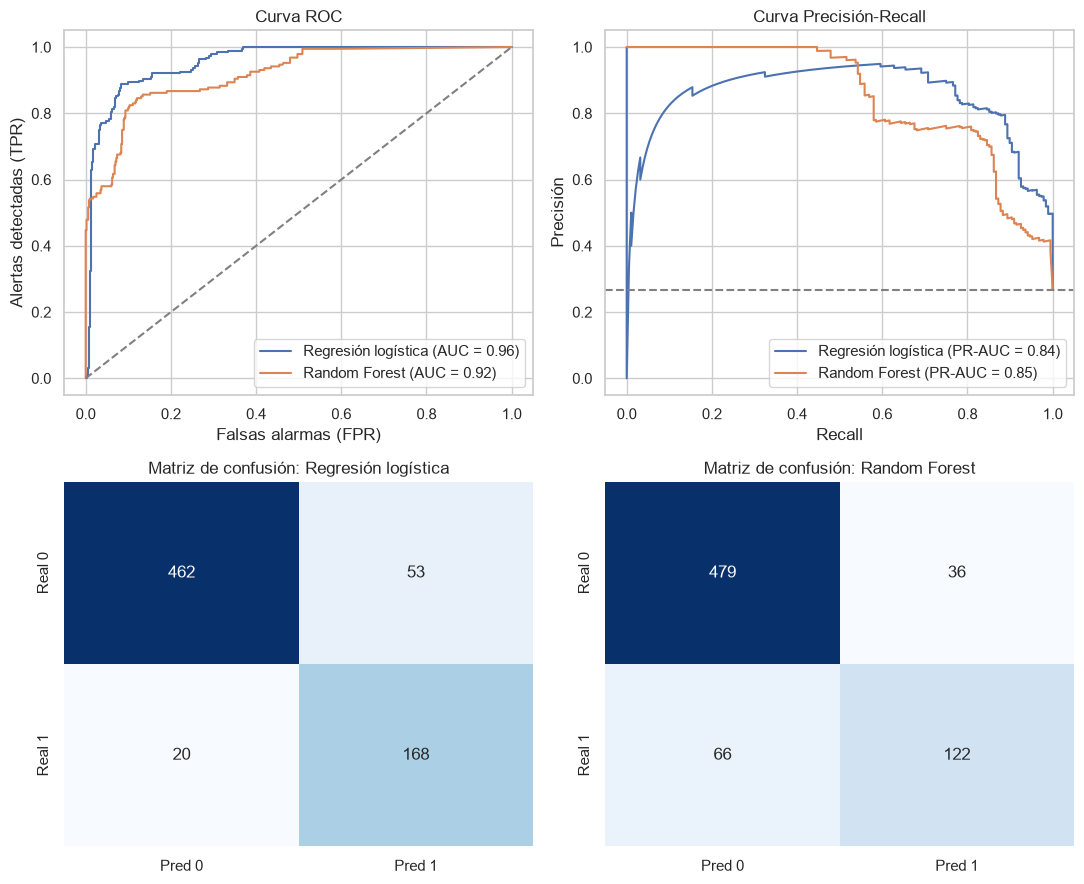

In [ ]:
def predicciones_oof(modelo):
    p = pd.Series(np.nan, index=X_dev.index)
    for tr, te in KFoldPorBloques(5).split(X_dev, y_dev):
        p.iloc[te] = clone(modelo).fit(X_dev.iloc[tr], y_dev.iloc[tr]).predict_proba(X_dev.iloc[te])[:, 1]
    return p

oof = {nombre: predicciones_oof(m) for nombre, m in mejores.items()}
candidatos = [(n, p, (p >= 0.5).astype(int)) for n, p in oof.items()]
candidatos += [("Persistencia", -X_dev["CotaMaz"], (X_dev["CotaMaz"] <= UMBRAL).astype(int)),
               ("Extrapolación lineal", -X_dev["cota_extrap14"], (X_dev["cota_extrap14"] <= UMBRAL).astype(int))]

tabla_m = pd.DataFrame({n: {"Precisión": precision_score(y_dev, pred), "Recall": recall_score(y_dev, pred),
                            "F1": f1_score(y_dev, pred), "ROC-AUC": roc_auc_score(y_dev, p),
                            "PR-AUC": average_precision_score(y_dev, p)} for n, p, pred in candidatos}).T.round(3)
print(tabla_m.to_string())

fig, axs = plt.subplots(2, 2, figsize=(11, 9))
for nombre, p in oof.items():
    fpr, tpr, _ = roc_curve(y_dev, p)
    axs[0, 0].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_dev, p):.2f})")
    precision, recall, _ = precision_recall_curve(y_dev, p)
    axs[0, 1].plot(recall, precision, label=f"{nombre} (PR-AUC = {average_precision_score(y_dev, p):.2f})")
axs[0, 0].plot([0, 1], [0, 1], "--", color="gray"); axs[0, 0].set_title("Curva ROC")
axs[0, 0].set_xlabel("Falsas alarmas (FPR)"); axs[0, 0].set_ylabel("Alertas detectadas (TPR)"); axs[0, 0].legend()
axs[0, 1].axhline(y_dev.mean(), ls="--", color="gray"); axs[0, 1].set_title("Curva Precisión-Recall")
axs[0, 1].set_xlabel("Recall"); axs[0, 1].set_ylabel("Precisión"); axs[0, 1].legend()
for ax, (nombre, p) in zip(axs[1], oof.items()):
    sns.heatmap(confusion_matrix(y_dev, p >= 0.5), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["Real 0", "Real 1"])
    ax.set_title(f"Matriz de confusión: {nombre}")
plt.tight_layout(); plt.show()

## 8. Visualización con t-SNE

Se proyectan a 2 dimensiones las variables que deja el filtro del pipeline, coloreando cada día con su **label**. Como las
variables vienen de series que cambian de forma gradual, se esperan trayectorias continuas con una zona de transición
entre clases, más que grupos totalmente separados [2].

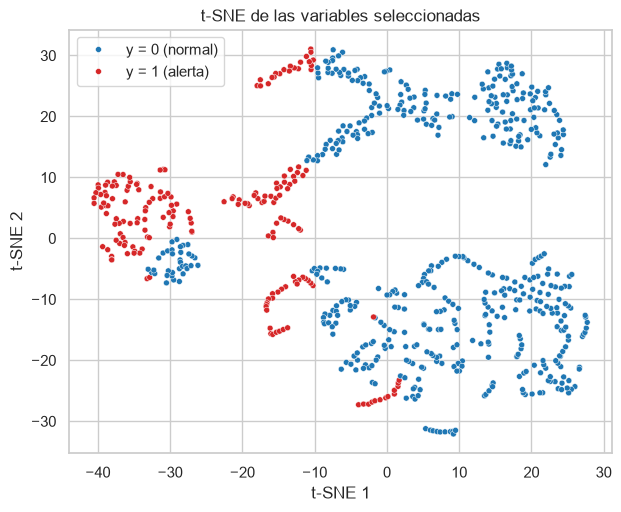

In [ ]:
modelo_rf = clone(mejores["Random Forest"]).fit(X_dev, y_dev)
Z = TSNE(perplexity=30, init="pca", random_state=SEED).fit_transform(modelo_rf[:-1].transform(X_dev))  # sin el clasificador
plt.figure(figsize=(7, 5.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y_dev.map({0: "y = 0 (normal)", 1: "y = 1 (alerta)"}).values,
                palette=["tab:blue", "tab:red"], s=18)
plt.title("t-SNE de las variables seleccionadas"); plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2"); plt.show()

## 9. Anticipación por episodio y falsas alarmas en 2025

Para evaluar cada evento de sequía, entrenamos el modelo con el resto del historial (2023–2024) aplicando una purga temporal de 14 días. La métrica principal es la anticipación de la primera alerta (p≥0.5) dentro de los 30 días previos a que el embalse caiga en cota crítica, considerando que marcas de 28 a 30 días pueden reflejar alertas prematuras antes de consolidarse la crisis.

In [ ]:
EPISODIOS = {"Oct–Nov 2023": ("2023-09-01", "2023-12-15"),
             "Mar–May 2024": ("2024-02-15", "2024-06-15"),
             "Sep–Dic 2024": ("2024-08-01", "2024-12-17")}
filas = []
for episodio, (ini, fin) in EPISODIOS.items():
    ini, fin = pd.Timestamp(ini), pd.Timestamp(fin)
    prueba = (X_dev.index >= ini) & (X_dev.index <= fin)
    entrena = (X_dev.index < ini - pd.Timedelta(days=PURGA)) | (X_dev.index > fin + pd.Timedelta(days=PURGA))
    Xp = X_dev[prueba]
    cruce = Xp.index[Xp["CotaMaz"] <= UMBRAL][0]                    # primer día con la cota bajo el umbral
    alertas = {nombre: clone(m).fit(X_dev[entrena], y_dev[entrena]).predict_proba(Xp)[:, 1] >= 0.5
               for nombre, m in mejores.items()}
    alertas["Extrapolación lineal"] = (Xp["cota_extrap14"] <= UMBRAL).values
    for nombre, alerta in alertas.items():
        previas = Xp.index[alerta & (Xp.index >= cruce - pd.Timedelta(days=30)) & (Xp.index <= cruce)]
        filas.append({"episodio": episodio, "modelo": nombre, "días de anticipación": (cruce - previas[0]).days if len(previas) else np.nan})
print(pd.DataFrame(filas).pivot(index="episodio", columns="modelo", values="días de anticipación").to_string())

modelo        Extrapolación lineal  Random Forest  Regresión logística
episodio                                                              
Mar–May 2024                  30.0            0.0                  NaN
Oct–Nov 2023                  18.0           17.0                 18.0
Sep–Dic 2024                  13.0            0.0                 14.0


**Falsas alarmas en 2025.** Todos los días de 2025 son clase 0, así que cualquier alerta es una falsa alarma.

In [ ]:
for nombre, m in mejores.items():
    alarmas = clone(m).fit(X_dev, y_dev).predict_proba(X_test)[:, 1] >= 0.5
    print(f"{nombre}: {int(alarmas.sum())} falsas alarmas en {len(X_test)} días")
print(f"Extrapolación lineal: {int((X_test['cota_extrap14'] <= UMBRAL).sum())} falsas alarmas en {len(X_test)} días")

Regresión logística: 0 falsas alarmas en 351 días
Random Forest: 0 falsas alarmas en 351 días
Extrapolación lineal: 0 falsas alarmas en 351 días


## 10. Conclusiones y consideraciones


**1. La Regresión Logística es el mejor modelo de ML para este proyecto**

Le ganó a Random Forest tanto en rendimiento global (PR-AUC de $0.942$ vs $0.911$) como en detectar los días en que arranca la crisis, lo cual se comprueba con las comparaciones de métricas que realizamos. Además, vimos que agregar datos de producción eléctrica no mejoró las predicciones.

**2. La física del agua es el predictor más fuerte**

Proyectar en el tiempo la velocidad con la que baja el embalse igualó a los modelos de Machine Learning en el resultado general ($0.949$) y la superó al capturar el inicio de las sequías ($0.858$). Esto nos demuestra que la inercia natural del vaciado contiene casi toda la información necesaria para predecir el riesgo.

**3. Es un modelo útil para la operación**

La Regresión Logística atrapó el $89\%$ de los días de crisis, dando entre 14 y 18 días de margen en dos de los tres episodios reales. Además, durante todo 2025 (un año sin crisis) tuvo cero falsas alarmas.

**4. Limitaciones y trabajo futuro**

 Solo pudimos probar el modelo en 3 episodios reales y predecimos riesgo en el embalse, no apagones (los cuales dependen también de plantas térmicas, importaciones y decisiones políticas). Si se requiere realizar una mejora a futuro de este proyecto se tienen que incluir datos de lluvias, demanda eléctrica y más años de registro.

## 11. Referencias

[1] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

[2] L. van der Maaten and G. Hinton, "Visualizing data using t-SNE," *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, 2008.

[3] L. Breiman, "Random forests," *Mach. Learn.*, vol. 45, no. 1, pp. 5–32, 2001.

[4] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bull.*, vol. 1, no. 6, pp. 80–83, 1945.

[5] C. Nadeau and Y. Bengio, "Inference for the generalization error," *Mach. Learn.*, vol. 52, no. 3, pp. 239–281, 2003.

[6] T. Saito and M. Rehmsmeier, "The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets," *PLoS ONE*, vol. 10, no. 3, Art. no. e0118432, 2015.

[7] CELEC EP, "Datos de hidrología y producción de energía," Ecuador. [Online]. Available: (URL de la página de CELEC). Accedido: (12/10/2026).

[8] Primicias, "Embalse de Mazar está a un metro de tocar el mínimo, ¿se agravarán los cortes de luz?" [Online]. Available: https://www.primicias.ec/economia/embalse-mazar-evolucion-crisis-cortes-luz-80860. Accedido: (13/10/2026).

[9] Primicias, "El agua del embalse de Mazar está debajo del nivel mínimo, vuelven los cortes de luz en abril." [Online]. Available: https://primicias.ec/noticias/economia/hidroelectrica-mazar-embalse-reservas-minimas-cortes-luz. Accedido: (13/10/2026).




**Declaración sobre el uso de Inteligencia Artificial Generativa**

Se utilizó Claude (Anthropic) como asistente para la estructura del notebook, el diseño de la validación y la redacción de parte del código. El autor revisó, ejecutó y comprobó los resultados.